# Selected cross-border neurodata interoperability figures and table

Place the original Excel matrix at `input_file/data-sharing-matrix.xlsx` relative to the notebook working directory, or edit `DATA_FILE` below. **The Excel data are external and are not embedded in this notebook.** Rows represent exporting jurisdictions and columns represent receiving jurisdictions. Self-transfers are excluded from profile statistics and asymmetry analyses, as in the original notebook.

Missing Python packages are installed in the active kernel. The first map run downloads Natural Earth 10m country boundaries; subsequent runs reuse `map_data_10m`. Internet access is required for missing packages and uncached map boundaries. For offline use, install the packages and provide the cached Natural Earth shapefile and its companion files in advance.

Figures are displayed below and saved as PNG and PDF in `outputs_selected`. The network summary table is displayed in its selected cell. The original category definitions, reference countries, clustering, colors, and map styling are retained, including the gray USA/Canada overlay.


## Configuration

Set the input matrix and output directory here before running the notebook.

In [1]:
from pathlib import Path

DATA_FILE = Path("input_file/data-sharing-matrix.xlsx")
OUTDIR = Path("outputs_selected")

if not DATA_FILE.is_file():
    raise FileNotFoundError(
        f"Excel matrix not found: {DATA_FILE.resolve()}. "
        "Copy the original data-sharing-matrix.xlsx here or update DATA_FILE."
    )
OUTDIR.mkdir(parents=True, exist_ok=True)


## Shared setup

Supporting cells run silently. Errors remain visible.

In [2]:
%%capture --no-stderr
# Core setup
# This cell installs missing libraries only when they are not already available.

import sys
import subprocess
import importlib.util
from pathlib import Path
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

def ensure_package(import_name, pip_name=None):
    """Import a package if available; otherwise install it in the active kernel."""
    if pip_name is None:
        pip_name = import_name

    if importlib.util.find_spec(import_name) is None:
        print(f"Installing missing package: {pip_name}")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pip_name])
    else:
        print(f"Package already installed: {import_name}")

# Packages required by the selected analyses only.
for import_name, pip_name in [
    ("openpyxl", "openpyxl"), ("numpy", "numpy"),
    ("pandas", "pandas"), ("matplotlib", "matplotlib"),
    ("scipy", "scipy"), ("networkx", "networkx"),
    ("geopandas", "geopandas"), ("pycountry", "pycountry"),
    ("IPython", "ipython"),
]:
    ensure_package(import_name, pip_name)

import math
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm, TwoSlopeNorm
import matplotlib.patches as mpatches

CATEGORY_ORDER = ["A1", "A2", "B", "C", "D", "E"]

CATEGORY_LABELS = [
    "A1 — directly enabled (same legal space)",
    "A2 — directly enabled (adequacy / high convergence)",
    "B — permissible with standard transfer tools (DTA)",
    "C — permissible but legally conditional / friction heavy",
    "D — restricted / difficult",
    "E — legally uncertain / not presently supported",
]

CATEGORY_TO_VALUE = {label: i for i, label in enumerate(CATEGORY_ORDER)}
VALUE_TO_CATEGORY = {v: k for k, v in CATEGORY_TO_VALUE.items()}

PALETTE = {
    "A1": "#4C9085",
    "A2": "#8AB9A7",
    "B":  "#D8C77A",
    "C":  "#D49A6A",
    "D":  "#B96B64",
    "E":  "#6E5A6A",
}

CMAP = ListedColormap([PALETTE[c] for c in CATEGORY_ORDER])
NORM = BoundaryNorm(np.arange(-0.5, len(CATEGORY_ORDER) + 0.5, 1), CMAP.N)

plt.rcParams["figure.dpi"] = 120


In [3]:
%%capture --no-stderr
# Data loading and reusable helper functions

COUNTRY_NAME_FIXES = {
    # United States variants
    "United States": "United States of America",
    "United States of America": "United States of America",
    "USA": "United States of America",
    "U.S.": "United States of America",
    "US": "United States of America",
    "U.S.A.": "United States of America",

    # United Kingdom variants
    "United Kingdom": "United Kingdom",
    "UK": "United Kingdom",
    "Great Britain": "United Kingdom",

    # North America
    "Canada": "Canada",
    "Mexico": "Mexico",

    # Europe
    "Czech Republic": "Czechia",
    "Czechia": "Czechia",

    # Africa / Natural Earth variants
    "Democratic Republic of the Congo": "Dem. Rep. Congo",
    "DR Congo": "Dem. Rep. Congo",
    "DRC": "Dem. Rep. Congo",
    "Congo, Democratic Republic of the": "Dem. Rep. Congo",
    "Republic of the Congo": "Congo",
    "Congo, Republic of the": "Congo",
    "Côte d’Ivoire": "Côte d'Ivoire",
    "Côte d'Ivoire": "Côte d'Ivoire",
    "Cote d'Ivoire": "Côte d'Ivoire",
    "Ivory Coast": "Côte d'Ivoire",
    "Eswatini": "eSwatini",
    "Swaziland": "eSwatini",
    "South Sudan": "S. Sudan",
    "Central African Republic": "Central African Rep.",
    "Equatorial Guinea": "Eq. Guinea",
    "Western Sahara": "W. Sahara",
    "Somaliland": "Somaliland",
    "Tanzania": "Tanzania",
    "United Republic of Tanzania": "Tanzania",

    # Latin America / Caribbean variants often encountered
    "Dominican Republic": "Dominican Rep.",
    "Trinidad and Tobago": "Trinidad and Tobago",
    "The Bahamas": "Bahamas",
    "Bahamas": "Bahamas",
}

def normalize_country_name(x):
    """Normalize one country/jurisdiction name for row-column and map matching."""
    if pd.isna(x):
        return x
    x = str(x).strip()
    x = " ".join(x.split())
    return COUNTRY_NAME_FIXES.get(x, x)

def load_directional_matrix(path):
    """Load and clean the directional compatibility matrix.

    Rows are origin/exporting jurisdictions.
    Columns are destination/receiving jurisdictions.

    Important: name harmonization is applied before row-column alignment.
    This prevents countries such as the United States or Canada from being
    dropped when their row and column labels use slightly different names.
    """
    raw = pd.read_excel(path, index_col=0)

    raw.index = raw.index.map(normalize_country_name)
    raw.columns = raw.columns.map(normalize_country_name)

    # Harmonize occasional miscoding.
    raw = raw.replace({"1A": "A1"})

    # If harmonization created duplicate rows or columns, keep the first.
    raw = raw.loc[~raw.index.duplicated(keep="first")]
    raw = raw.loc[:, ~raw.columns.duplicated(keep="first")]

    rows = set(raw.index)
    cols = set(raw.columns)
    row_only = sorted(rows - cols)
    col_only = sorted(cols - rows)

    print(f"Rows in raw matrix: {len(raw.index)}")
    print(f"Columns in raw matrix: {len(raw.columns)}")
    print(f"Rows not present as columns: {row_only}")
    print(f"Columns not present as rows: {col_only}")

    common = [c for c in raw.index if c in raw.columns]
    df = raw.loc[common, common]

    print(f"Jurisdictions retained after row-column alignment: {len(df.index)}")
    print("North America check after alignment:")
    print([c for c in df.index if any(s in c.lower() for s in ["canada", "united", "america", "mexico", "usa"])])

    return df

def categorical_to_numeric(df):
    """Convert legal categories to ordinal numeric values."""
    return df.replace(CATEGORY_TO_VALUE).apply(pd.to_numeric, errors="coerce")

def remove_self_transfers(df):
    """Return a copy of df with diagonal/self-transfers set to NaN.

    This avoids modifying df.values directly, which can trigger
    `ValueError: underlying array is read-only` in some environments.
    """
    arr = df.to_numpy(copy=True, dtype=object)
    np.fill_diagonal(arr, np.nan)
    return pd.DataFrame(arr, index=df.index.copy(), columns=df.columns.copy())

def mode_or_nan(values):
    counts = pd.Series(values).dropna().value_counts()
    if counts.empty:
        return np.nan
    return counts.idxmax()

def add_category_colorbar(
    fig,
    ax,
    im,
    label="Directional Transfer Compatibility Class"
):
    cbar = fig.colorbar(
        im,
        ax=ax,
        ticks=range(len(CATEGORY_ORDER)),
        fraction=0.07,
        pad=0.08
    )

    cbar.ax.set_yticklabels(CATEGORY_LABELS, fontsize=16)
    cbar.ax.tick_params(labelsize=16)

    # Move the label to the left side
    cbar.ax.yaxis.set_label_position("left")

    cbar.set_label(
        label,
        fontsize=25,
        fontweight="bold",
        labelpad=25,
    )

    return cbar

def savefig(fig, name):
    fig.savefig(OUTDIR / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(OUTDIR / f"{name}.pdf", bbox_inches="tight")

df = load_directional_matrix(DATA_FILE)
df_no_self = remove_self_transfers(df)

numeric = categorical_to_numeric(df)
numeric_no_self = categorical_to_numeric(df_no_self)



In [4]:
%%capture --no-stderr
# Robust map setup using controlled ISO-3 matching and 10m Natural Earth boundaries
# Replace the current map setup / mode_df / merge cell with this entire cell.

import sys
import subprocess
import importlib.util
from pathlib import Path
import zipfile
import urllib.request

def ensure_package(import_name, pip_name=None):
    if pip_name is None:
        pip_name = import_name
    if importlib.util.find_spec(import_name) is None:
        print(f"Installing missing package: {pip_name}")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pip_name])

ensure_package("geopandas")
ensure_package("pycountry")

import geopandas as gpd
import pycountry

NATURAL_EARTH_URL = (
    "https://naturalearth.s3.amazonaws.com/"
    "10m_cultural/ne_10m_admin_0_countries.zip"
)

MAP_DIR = Path("map_data_10m")
MAP_DIR.mkdir(exist_ok=True)

ZIP_FILE = MAP_DIR / "ne_10m_admin_0_countries.zip"
WORLD_FILE = MAP_DIR / "ne_10m_admin_0_countries.shp"

if not WORLD_FILE.exists():
    print("Downloading Natural Earth 10m country boundaries...")
    urllib.request.urlretrieve(NATURAL_EARTH_URL, ZIP_FILE)
    with zipfile.ZipFile(ZIP_FILE, "r") as z:
        z.extractall(MAP_DIR)

world = gpd.read_file(WORLD_FILE)

iso_candidates = ["ADM0_A3", "ISO_A3", "SOV_A3"]
iso_col = next((c for c in iso_candidates if c in world.columns), None)

if iso_col is None:
    raise ValueError(
        f"No ISO-3 country code column found. Available columns: {list(world.columns)}"
    )

print(f"Using Natural Earth ISO column: {iso_col}")

COUNTRY_TO_ISO3 = {
    # North America
    "Canada": "CAN",
    "Mexico": "MEX",
    "United States": "USA",
    "United States of America": "USA",
    "USA": "USA",
    "US": "USA",
    "U.S.": "USA",
    "U.S.A.": "USA",

    # Europe / UK
    "United Kingdom": "GBR",
    "UK": "GBR",
    "Great Britain": "GBR",
    "Czechia": "CZE",
    "Czech Republic": "CZE",

    # Africa
    "Algeria": "DZA",
    "Angola": "AGO",
    "Benin": "BEN",
    "Botswana": "BWA",
    "Burkina Faso": "BFA",
    "Cabo Verde": "CPV",
    "Cape Verde": "CPV",
    "Cameroon": "CMR",
    "Comoros": "COM",
    "Republic of the Congo": "COG",
    "Congo, Republic of the": "COG",
    "Congo": "COG",
    "Democratic Republic of the Congo": "COD",
    "Dem. Rep. Congo": "COD",
    "Congo, Democratic Republic of the": "COD",
    "DR Congo": "COD",
    "DRC": "COD",
    "Cote d'Ivoire": "CIV",
    "Côte d'Ivoire": "CIV",
    "Côte d’Ivoire": "CIV",
    "Ivory Coast": "CIV",
    "Djibouti": "DJI",
    "Egypt": "EGY",
    "Eswatini": "SWZ",
    "Swaziland": "SWZ",
    "Ethiopia": "ETH",
    "Gabon": "GAB",
    "Ghana": "GHA",
    "Guinea": "GIN",
    "Kenya": "KEN",
    "Lesotho": "LSO",
    "Liberia": "LBR",
    "Libya": "LBY",
    "Madagaskar": "MDG",
    "Madagascar": "MDG",
    "Malawi": "MWI",
    "Mauritania": "MRT",
    "Mauritius": "MUS",
    "Morocco": "MAR",
    "Mozambique": "MOZ",
    "Namibia": "NAM",
    "Nigeria": "NGA",
    "Rwanda": "RWA",
    "Sao Tome and Principe": "STP",
    "São Tomé and Príncipe": "STP",
    "Senegal": "SEN",
    "Seychelles": "SYC",
    "Sierra Leone": "SLE",
    "South Africa": "ZAF",
    "Tanzania": "TZA",
    "United Republic of Tanzania": "TZA",
    "The Gambia": "GMB",
    "Gambia": "GMB",
    "Togo": "TGO",
    "Tunisia": "TUN",
    "Uganda": "UGA",
    "Zambia": "ZMB",
    "Zimbabwe": "ZWE",

    # Latin America / Caribbean
    "Argentina": "ARG",
    "Barbados": "BRB",
    "Belize": "BLZ",
    "Bolivia": "BOL",
    "Brazil": "BRA",
    "Chile": "CHL",
    "Colombia": "COL",
    "Costa Rica": "CRI",
    "Cuba": "CUB",
    "Dominica": "DMA",
    "Dominican Republic": "DOM",
    "Dominican Rep.": "DOM",
    "Ecuador": "ECU",
    "El Salvador": "SLV",
    "Grenada": "GRD",
    "Guatemala": "GTM",
    "Guyana": "GUY",
    "Honduras": "HND",
    "Jamaica": "JAM",
    "Nicaragua": "NIC",
    "Panama": "PAN",
    "Paraguay": "PRY",
    "Peru": "PER",
    "Saint Lucia": "LCA",
    "Trinidad and Tobago": "TTO",
    "Uruguay": "URY",
}

def country_to_iso3(name):
    name = str(name).strip()

    if name in COUNTRY_TO_ISO3:
        return COUNTRY_TO_ISO3[name]

    try:
        return pycountry.countries.lookup(name).alpha_3
    except LookupError:
        return None

world["ne_iso_a3"] = world[iso_col].astype(str).str.strip()
world = world[world["ne_iso_a3"] != "-99"].copy()


In [5]:
# Dependency for the selected asymmetry network; no figure or table is generated.
asymmetry = numeric - numeric.T
asymmetry = remove_self_transfers(asymmetry).apply(pd.to_numeric, errors="coerce")


## 1. Import and export compatibility diversity

Shannon entropy summarizes the diversity of each jurisdiction’s incoming and outgoing compatibility classes. The selected cell produces two maps.

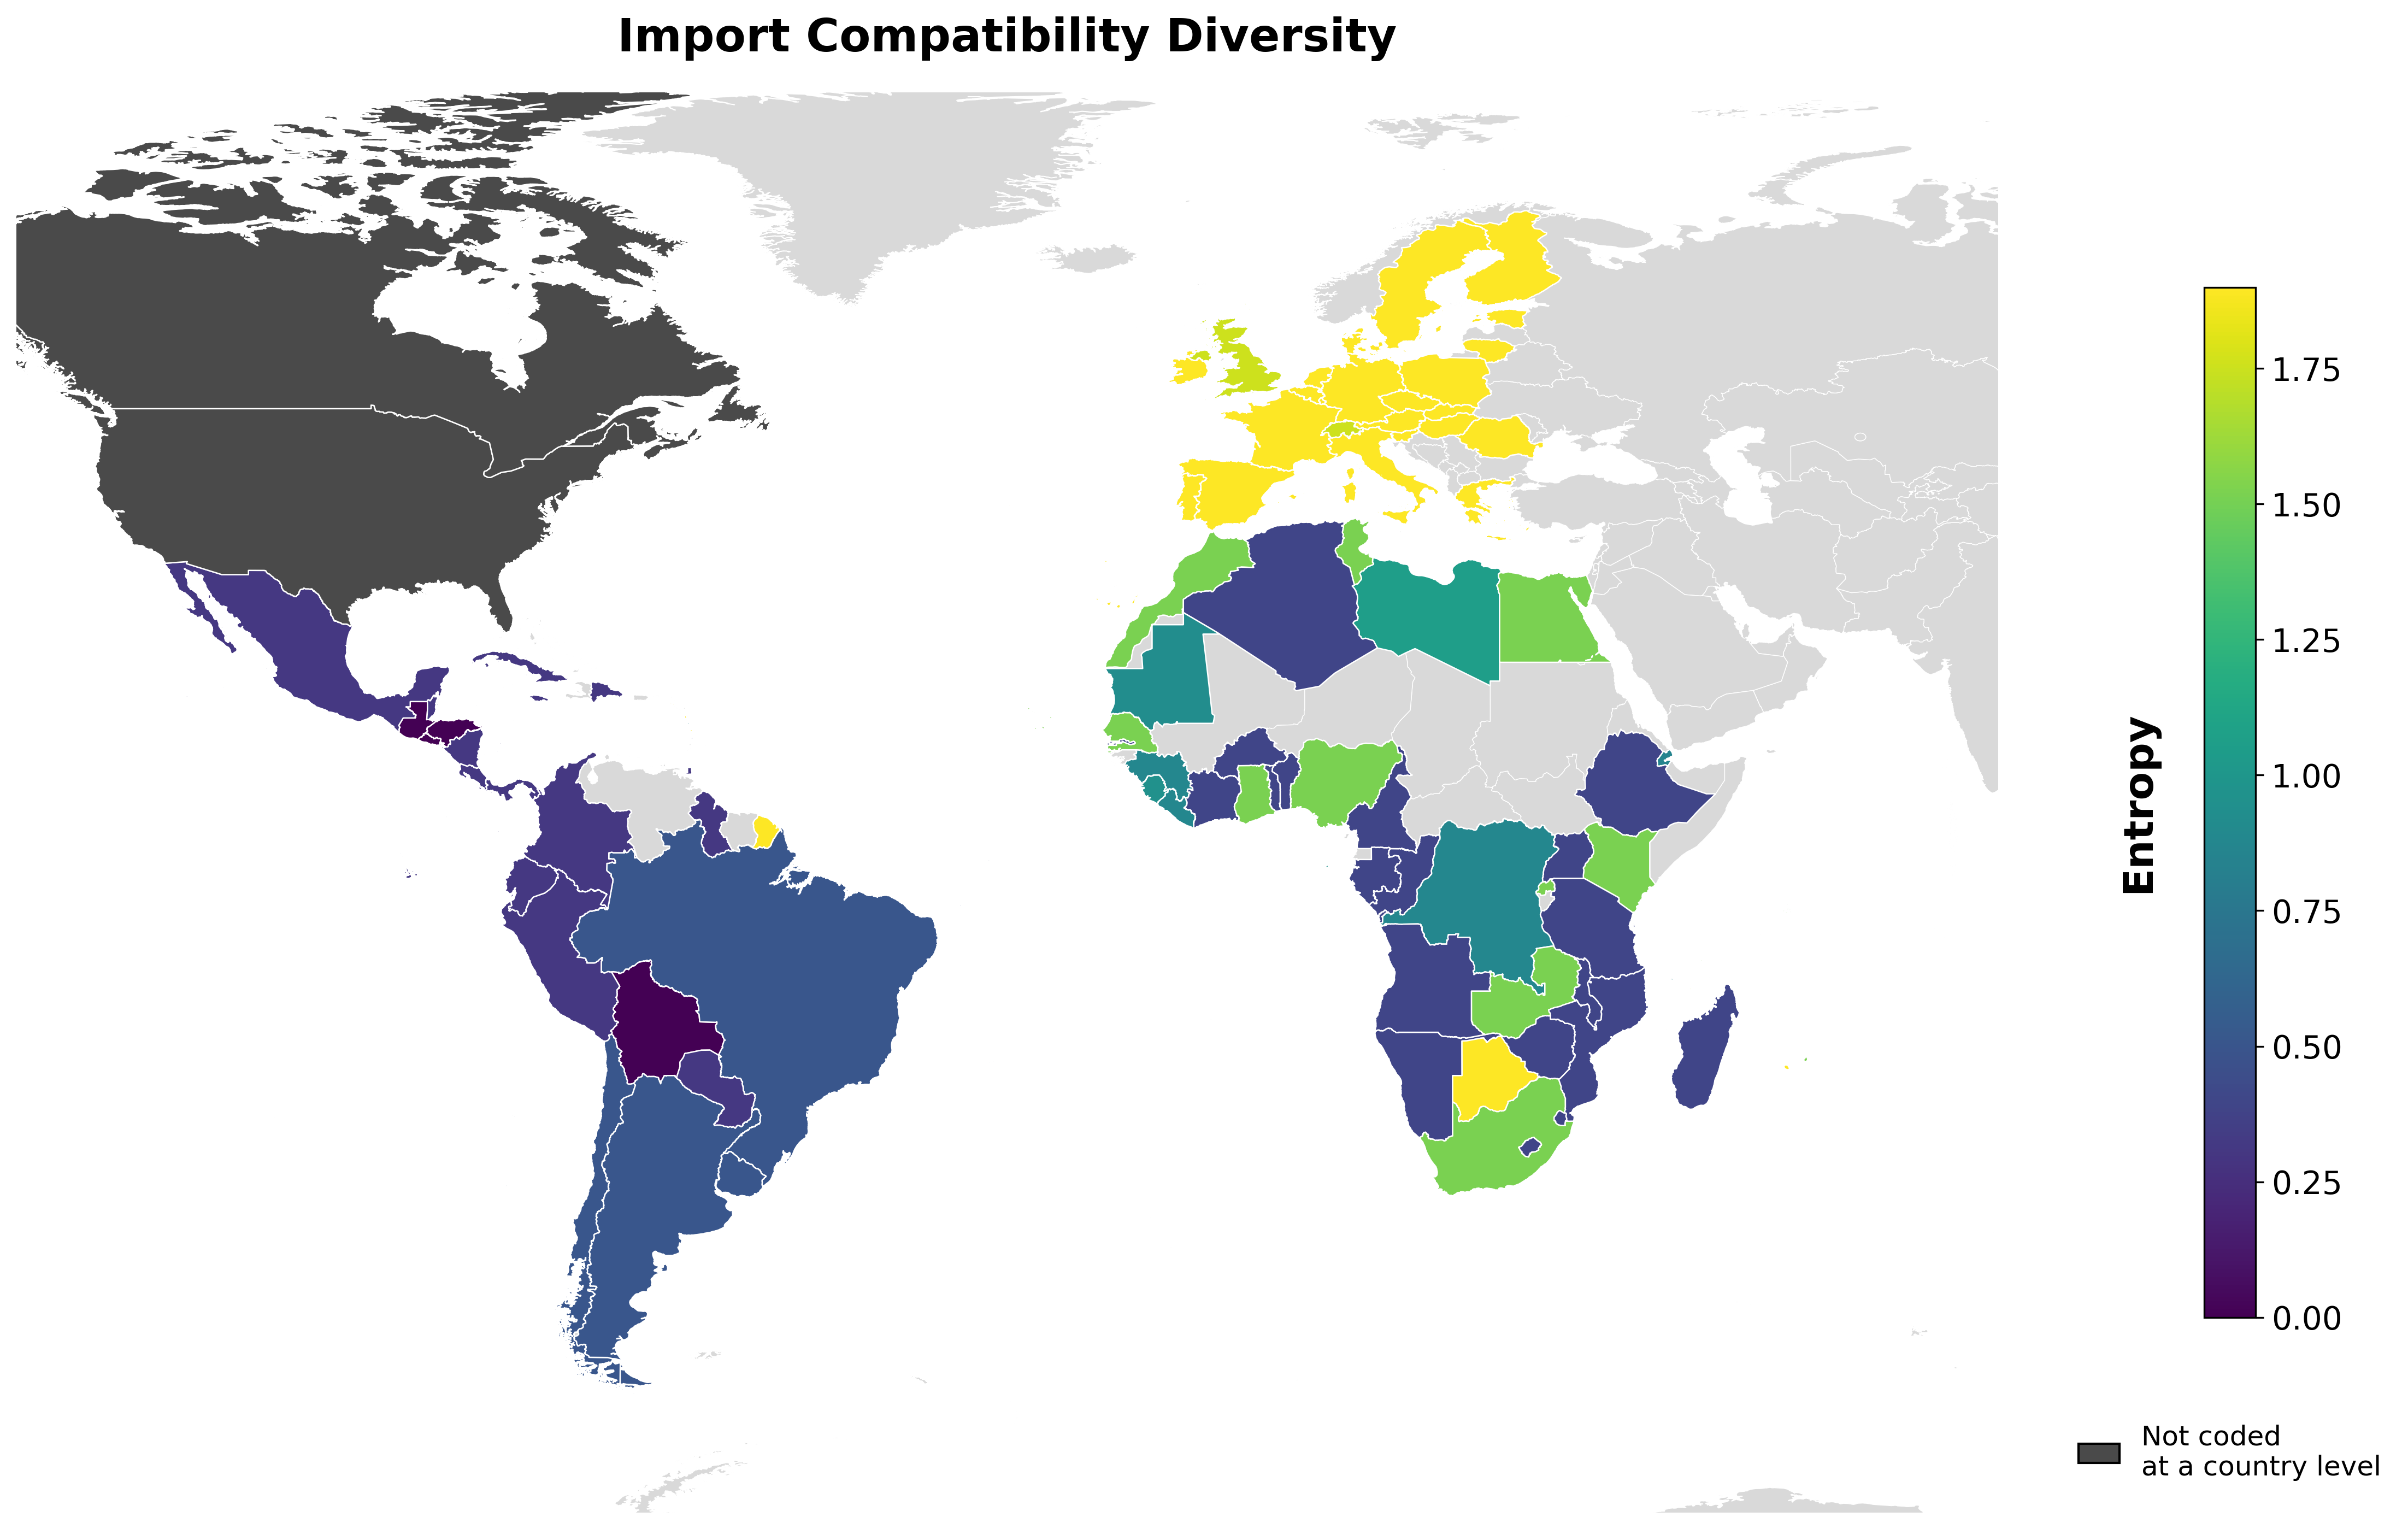

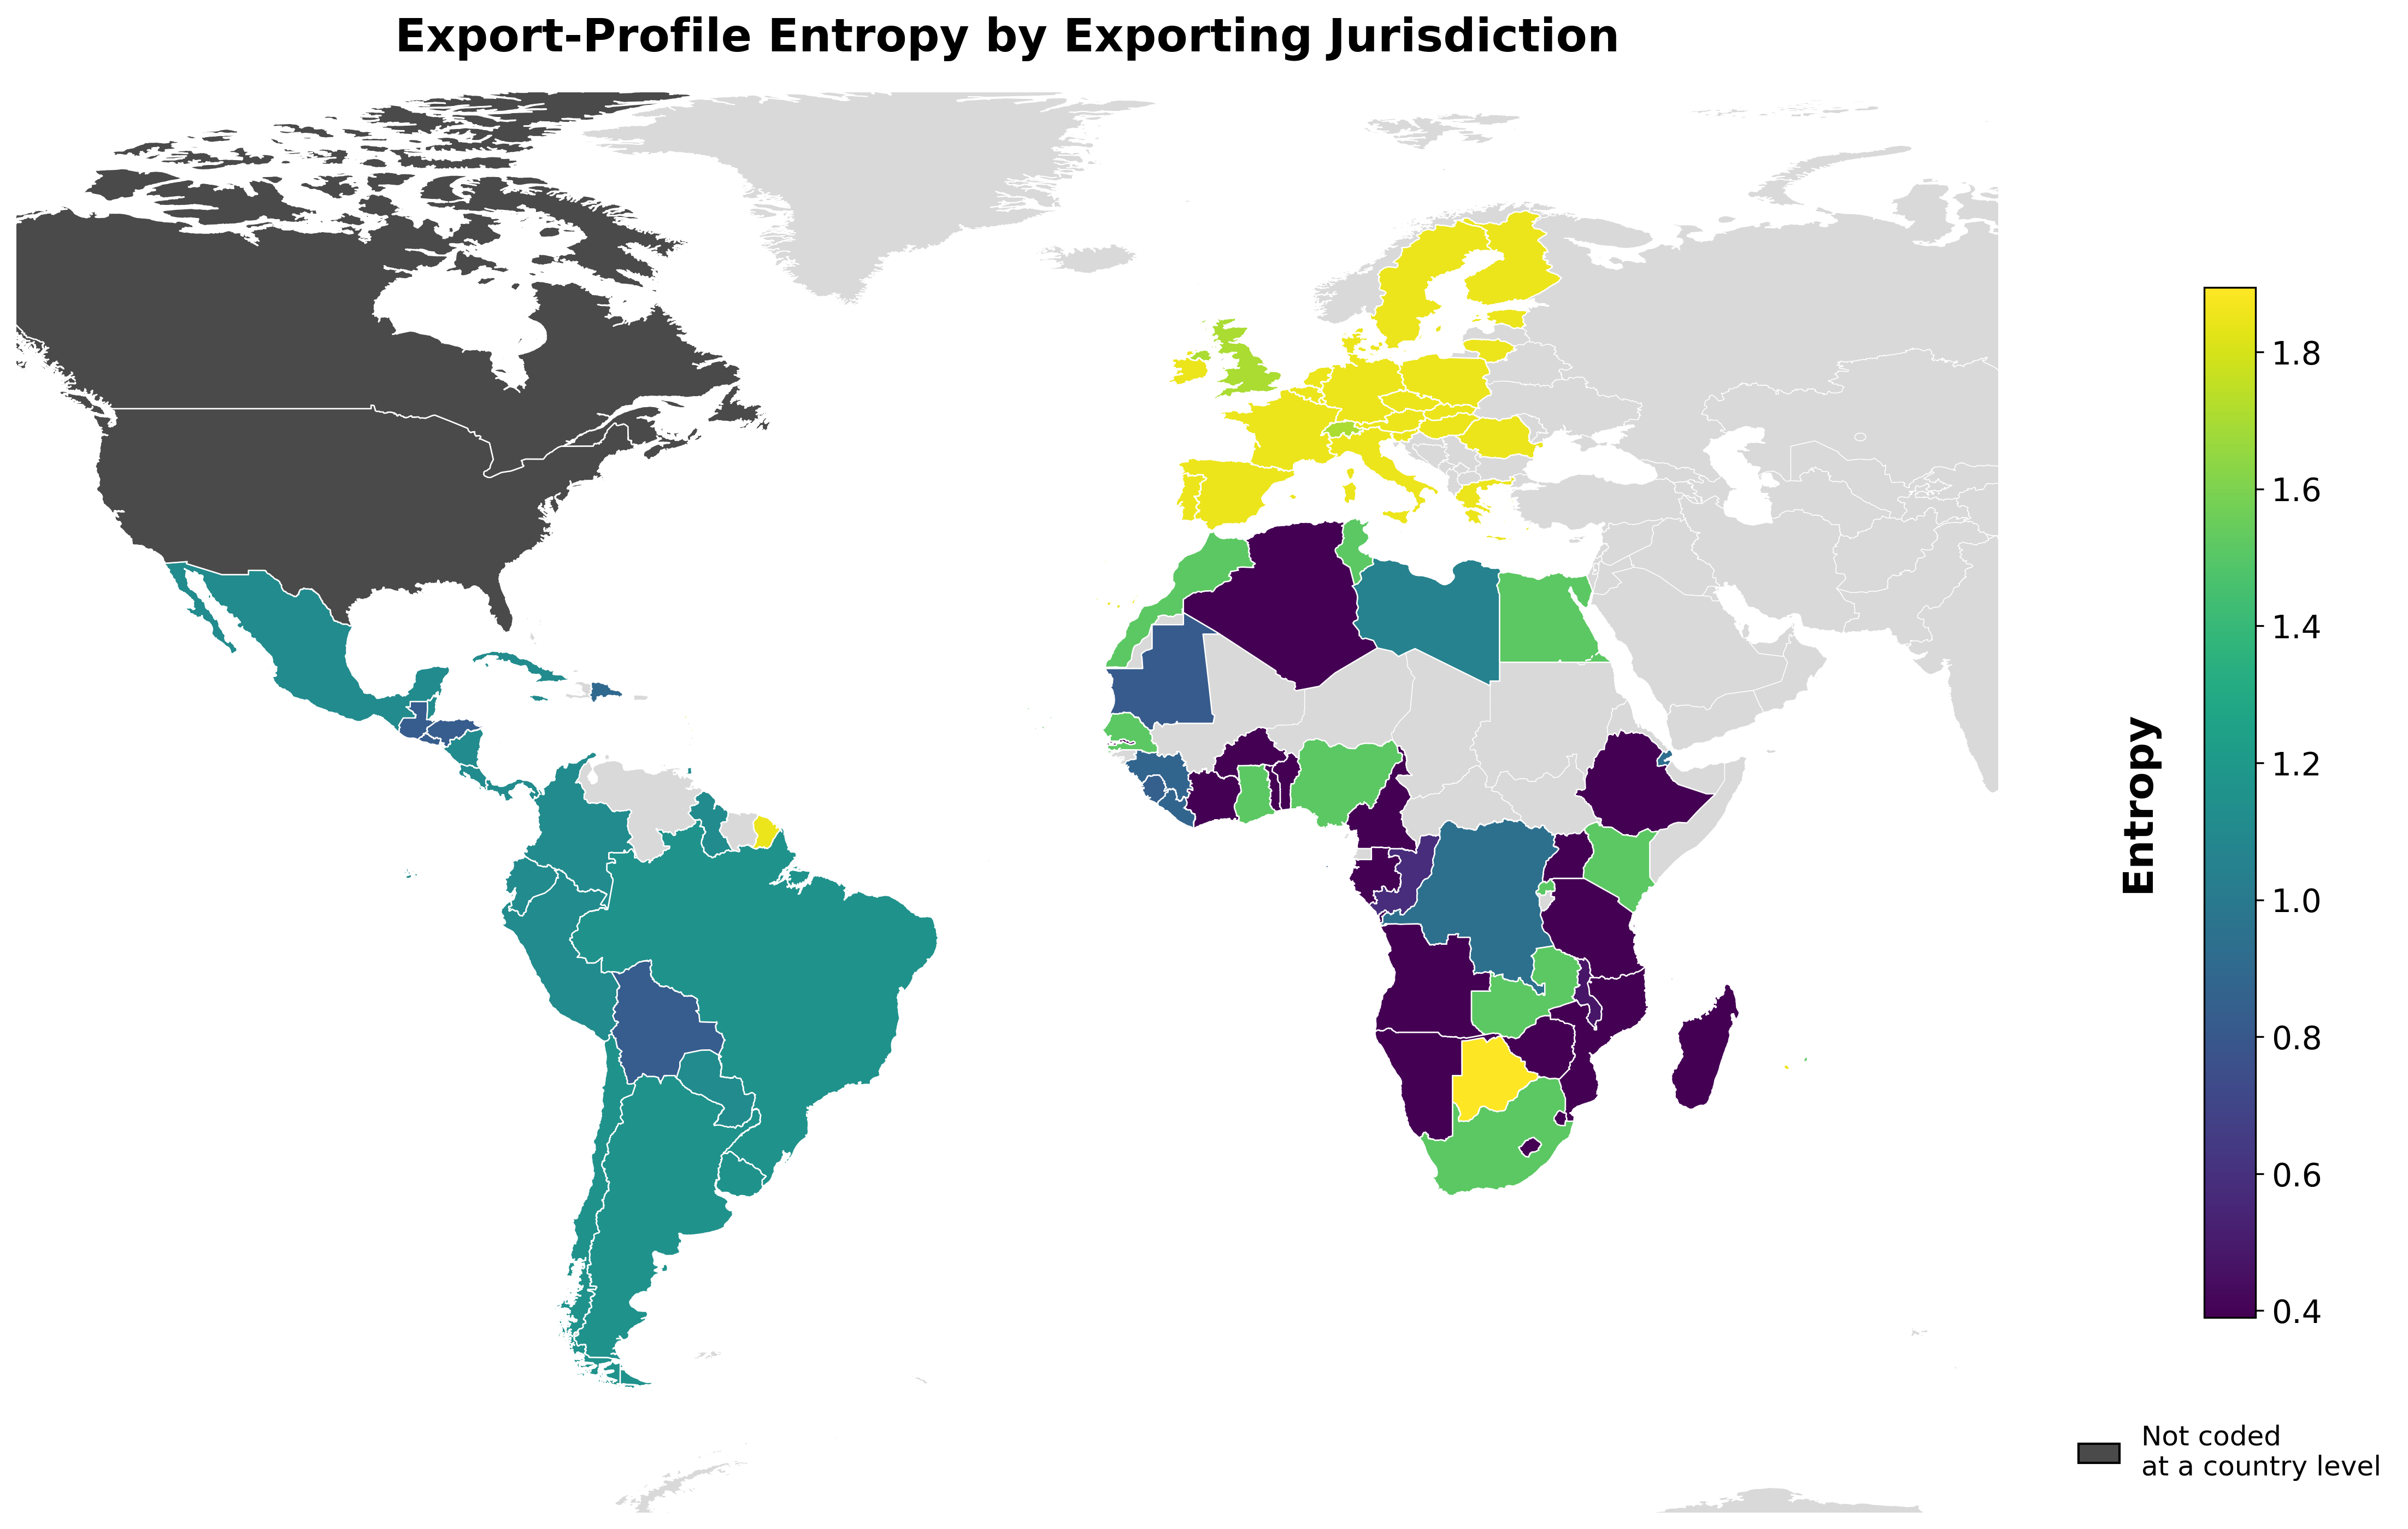

In [6]:
# USE USE
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

# --------------------------------------------------
# Shannon entropy
# --------------------------------------------------
def shannon_entropy(values):
    values = pd.Series(values).dropna()
    if values.empty:
        return np.nan
    p = values.value_counts(normalize=True)
    return float(-(p * np.log2(p)).sum())

entropy_map_df = pd.DataFrame({
    "country": df_no_self.index,
    "export_entropy": df_no_self.apply(
        lambda row: shannon_entropy(row.values),
        axis=1
    ).values,
    "import_entropy": df_no_self.apply(
        lambda col: shannon_entropy(col.values),
        axis=0
    ).reindex(df_no_self.index).values,
})

entropy_map_df["iso_a3"] = entropy_map_df["country"].map(country_to_iso3)

entropy_merged = world.merge(
    entropy_map_df,
    left_on="ne_iso_a3",
    right_on="iso_a3",
    how="left",
)

# --------------------------------------------------
# Plot function
# --------------------------------------------------
def plot_entropy_map(column, title, outfile_base):

    matched_geo = entropy_merged[
        entropy_merged[column].notna()
    ].copy()

    fig, ax = plt.subplots(figsize=(16, 10), dpi=300)

    # Background
    world.plot(
        ax=ax,
        color="#D9D9D9",
        edgecolor="white",
        linewidth=0.35,
        zorder=1,
    )

    # Entropy layer
    matched_geo.plot(
        column=column,
        ax=ax,
        cmap="viridis",
        legend=True,
        edgecolor="white",
        linewidth=0.6,
        zorder=2,
        legend_kwds={
            "shrink": 0.65,
            "pad": 0.08,
        },
    )

    # ---------------------------------------------
    # Force USA and Canada to dark gray
    # ---------------------------------------------
    usa_canada = world[
        world["ne_iso_a3"].isin(["USA", "CAN"])
    ]

    usa_canada.plot(
        ax=ax,
        color="#4A4A4A",
        edgecolor="white",
        linewidth=0.6,
        zorder=3,
    )

    # ---------------------------------------------
    # Zoom
    # ---------------------------------------------
    minx, miny, maxx, maxy = matched_geo.total_bounds

    ax.set_xlim(
        minx - (maxx - minx) * 0.08,
        maxx + (maxx - minx) * 0.08,
    )

    ax.set_ylim(
        miny - (maxy - miny) * 0.10,
        maxy + (maxy - miny) * 0.10,
    )

    ax.set_aspect("equal", adjustable="box")

    # ---------------------------------------------
    # Title
    # ---------------------------------------------
    ax.set_title(
        title,
        fontsize=20,
        fontweight="bold",
        pad=18,
    )

    ax.axis("off")

    # ---------------------------------------------
    # Colorbar formatting
    # ---------------------------------------------
    cbar_ax = fig.axes[-1]

    cbar_ax.tick_params(labelsize=14)

    cbar_ax.yaxis.set_label_position("left")

    cbar_ax.set_ylabel(
        "Entropy",
        fontsize=18,
        fontweight="bold",
        labelpad=20,
    )

    # ---------------------------------------------
    # Gray legend beneath colorbar
    # ---------------------------------------------
    gray_patch = Patch(
        facecolor="#4A4A4A",
        edgecolor="black",
        label="Not coded\nat a country level",
    )

    cbar_ax.legend(
        handles=[gray_patch],
        loc="upper center",
        bbox_to_anchor=(0.5, -0.08),
        frameon=False,
        fontsize=12,
        handlelength=1.5,
    )

    fig.tight_layout()

    savefig(fig, outfile_base)

    plt.show()
    plt.close(fig)

# --------------------------------------------------
# Create maps
# --------------------------------------------------
plot_entropy_map(
    "import_entropy",
    "Import Compatibility Diversity",
    "03g_world_map_import_entropy_publication",
)

plot_entropy_map(
    "export_entropy",
    "Export-Profile Entropy by Exporting Jurisdiction",
    "03h_world_map_export_entropy_publication",
)

## 2. Europe/UK reference maps

The selected cell displays modal export compatibility to, and import compatibility from, the original Europe/UK reference set.

Reference countries retained:
['United Kingdom', 'Germany', 'France', 'Italy', 'Spain', 'Netherlands', 'Belgium', 'Sweden', 'Austria', 'Finland', 'Ireland', 'Denmark', 'Luxembourg', 'Czechia', 'Portugal', 'Lithuania', 'Estonia', 'Poland', 'Greece', 'Hungary', 'Slovakia', 'Slovenia', 'Romania', 'Switzerland']


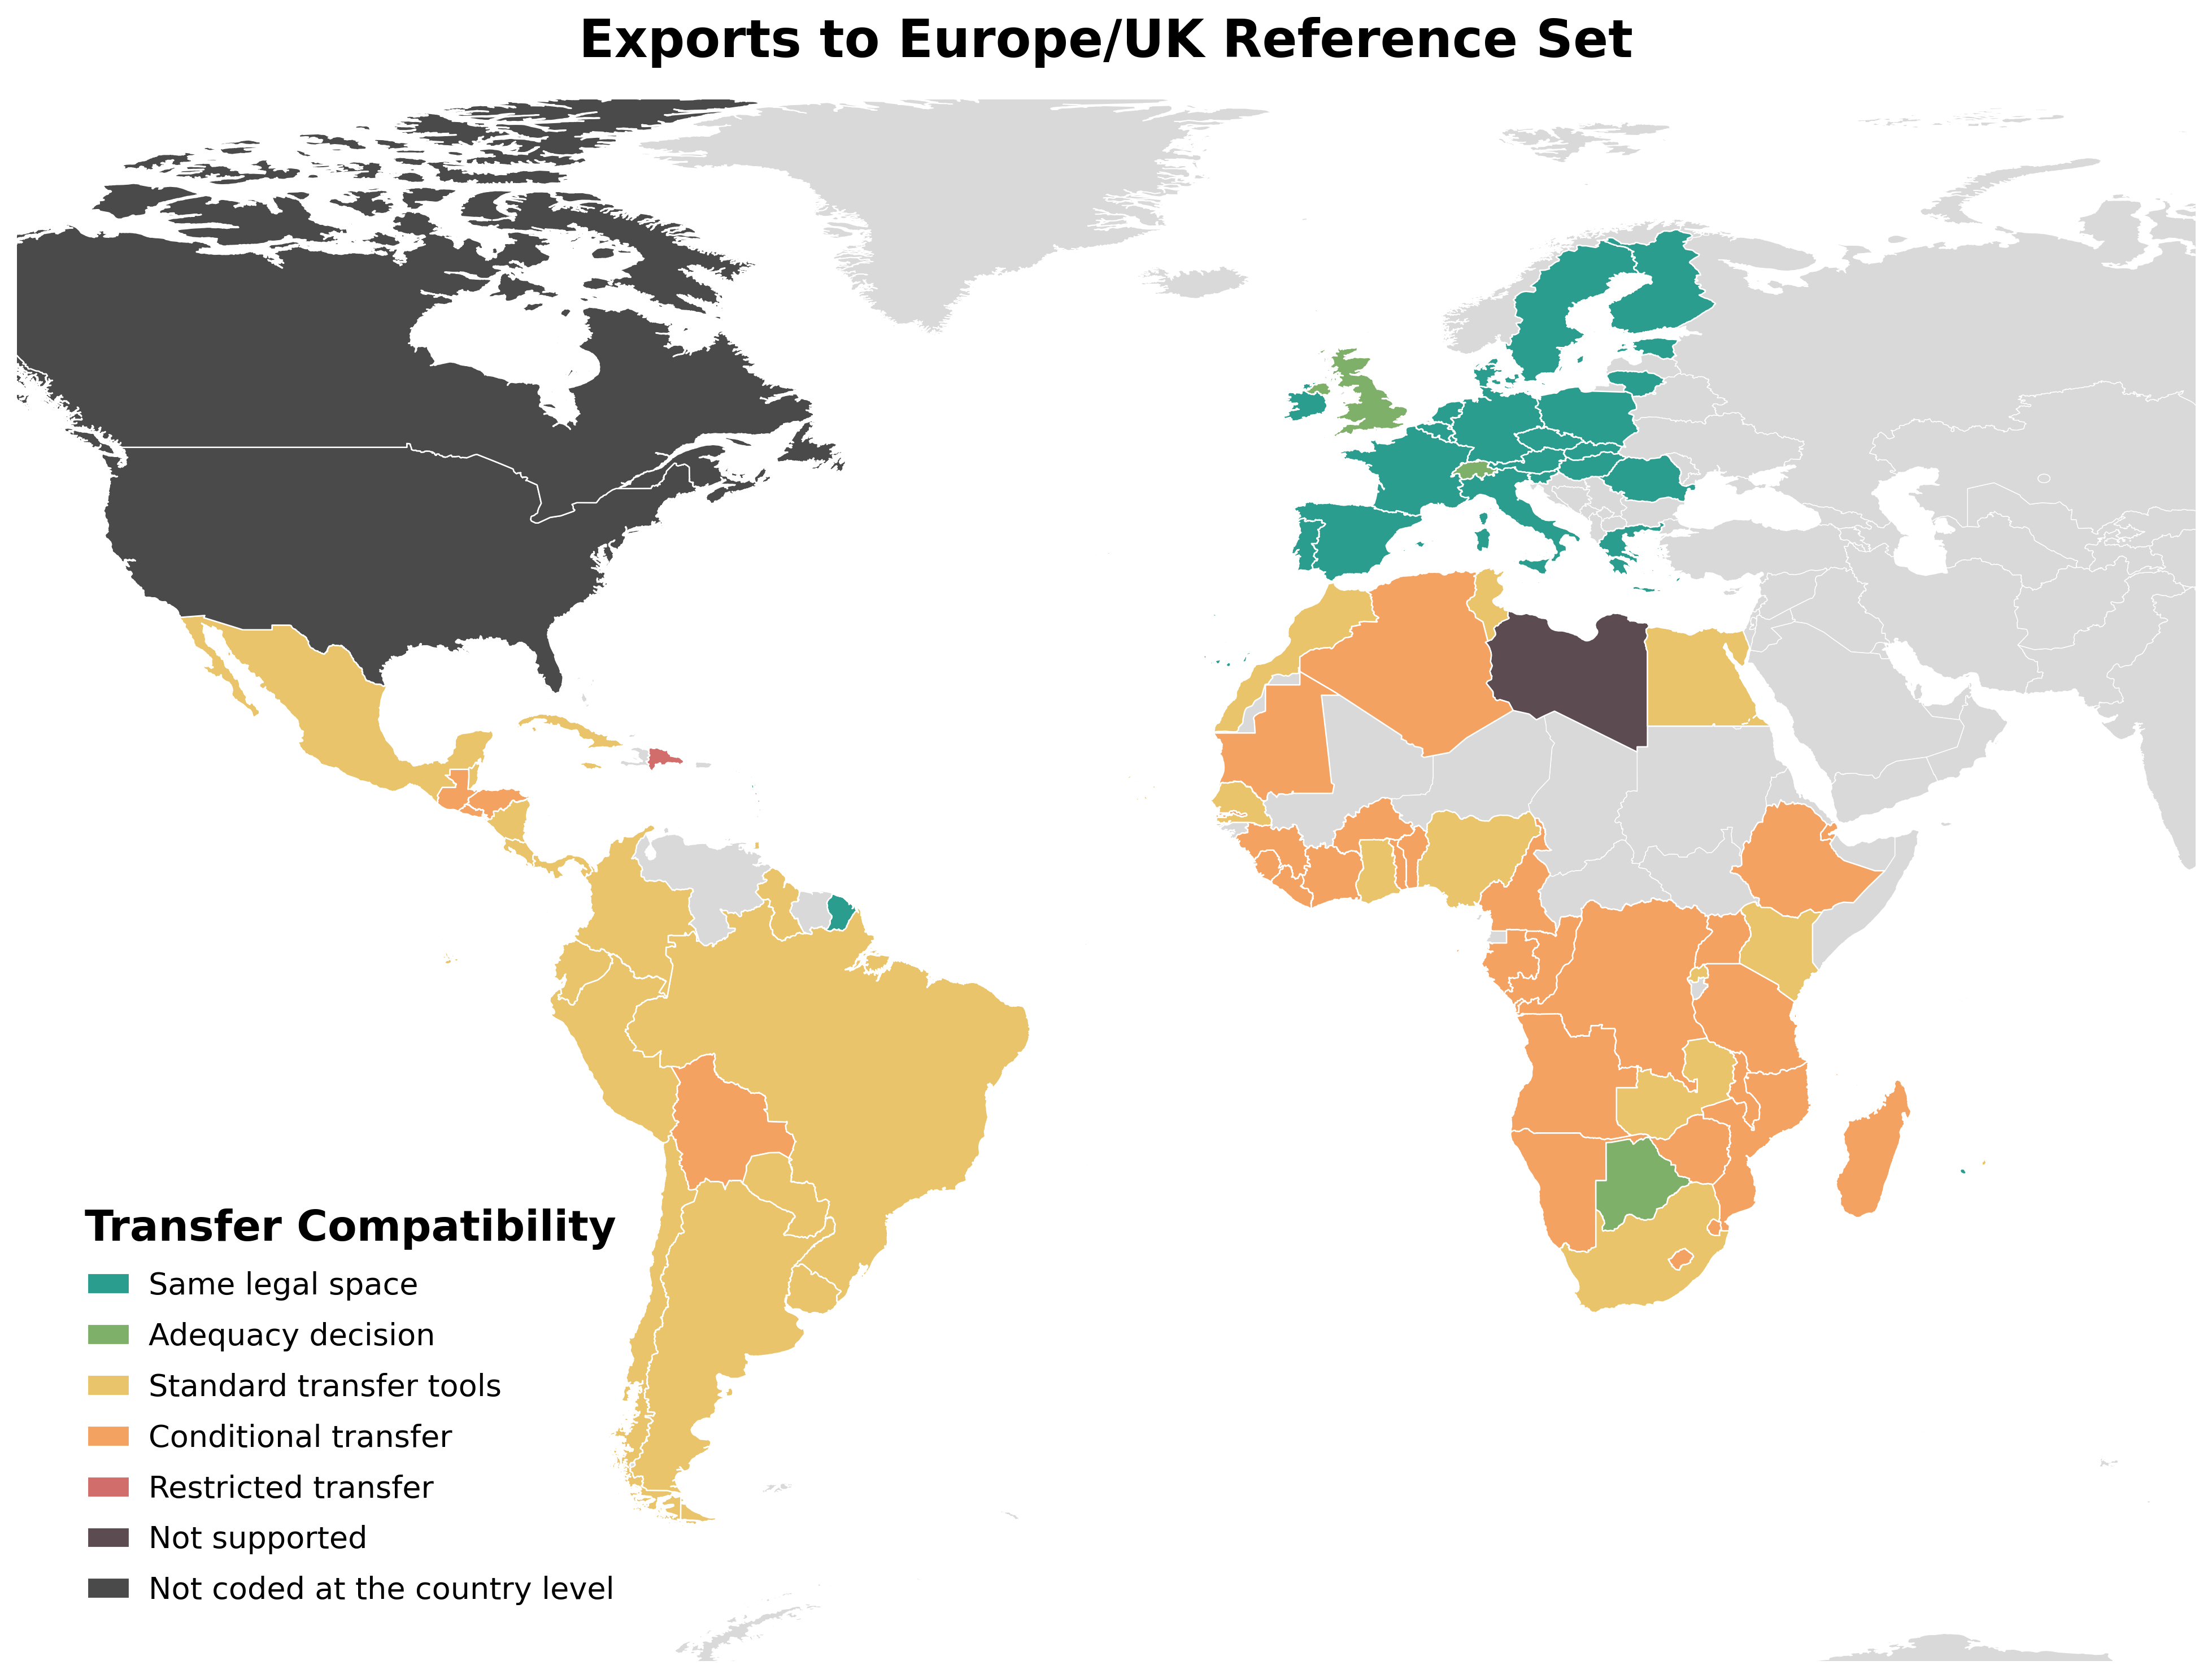

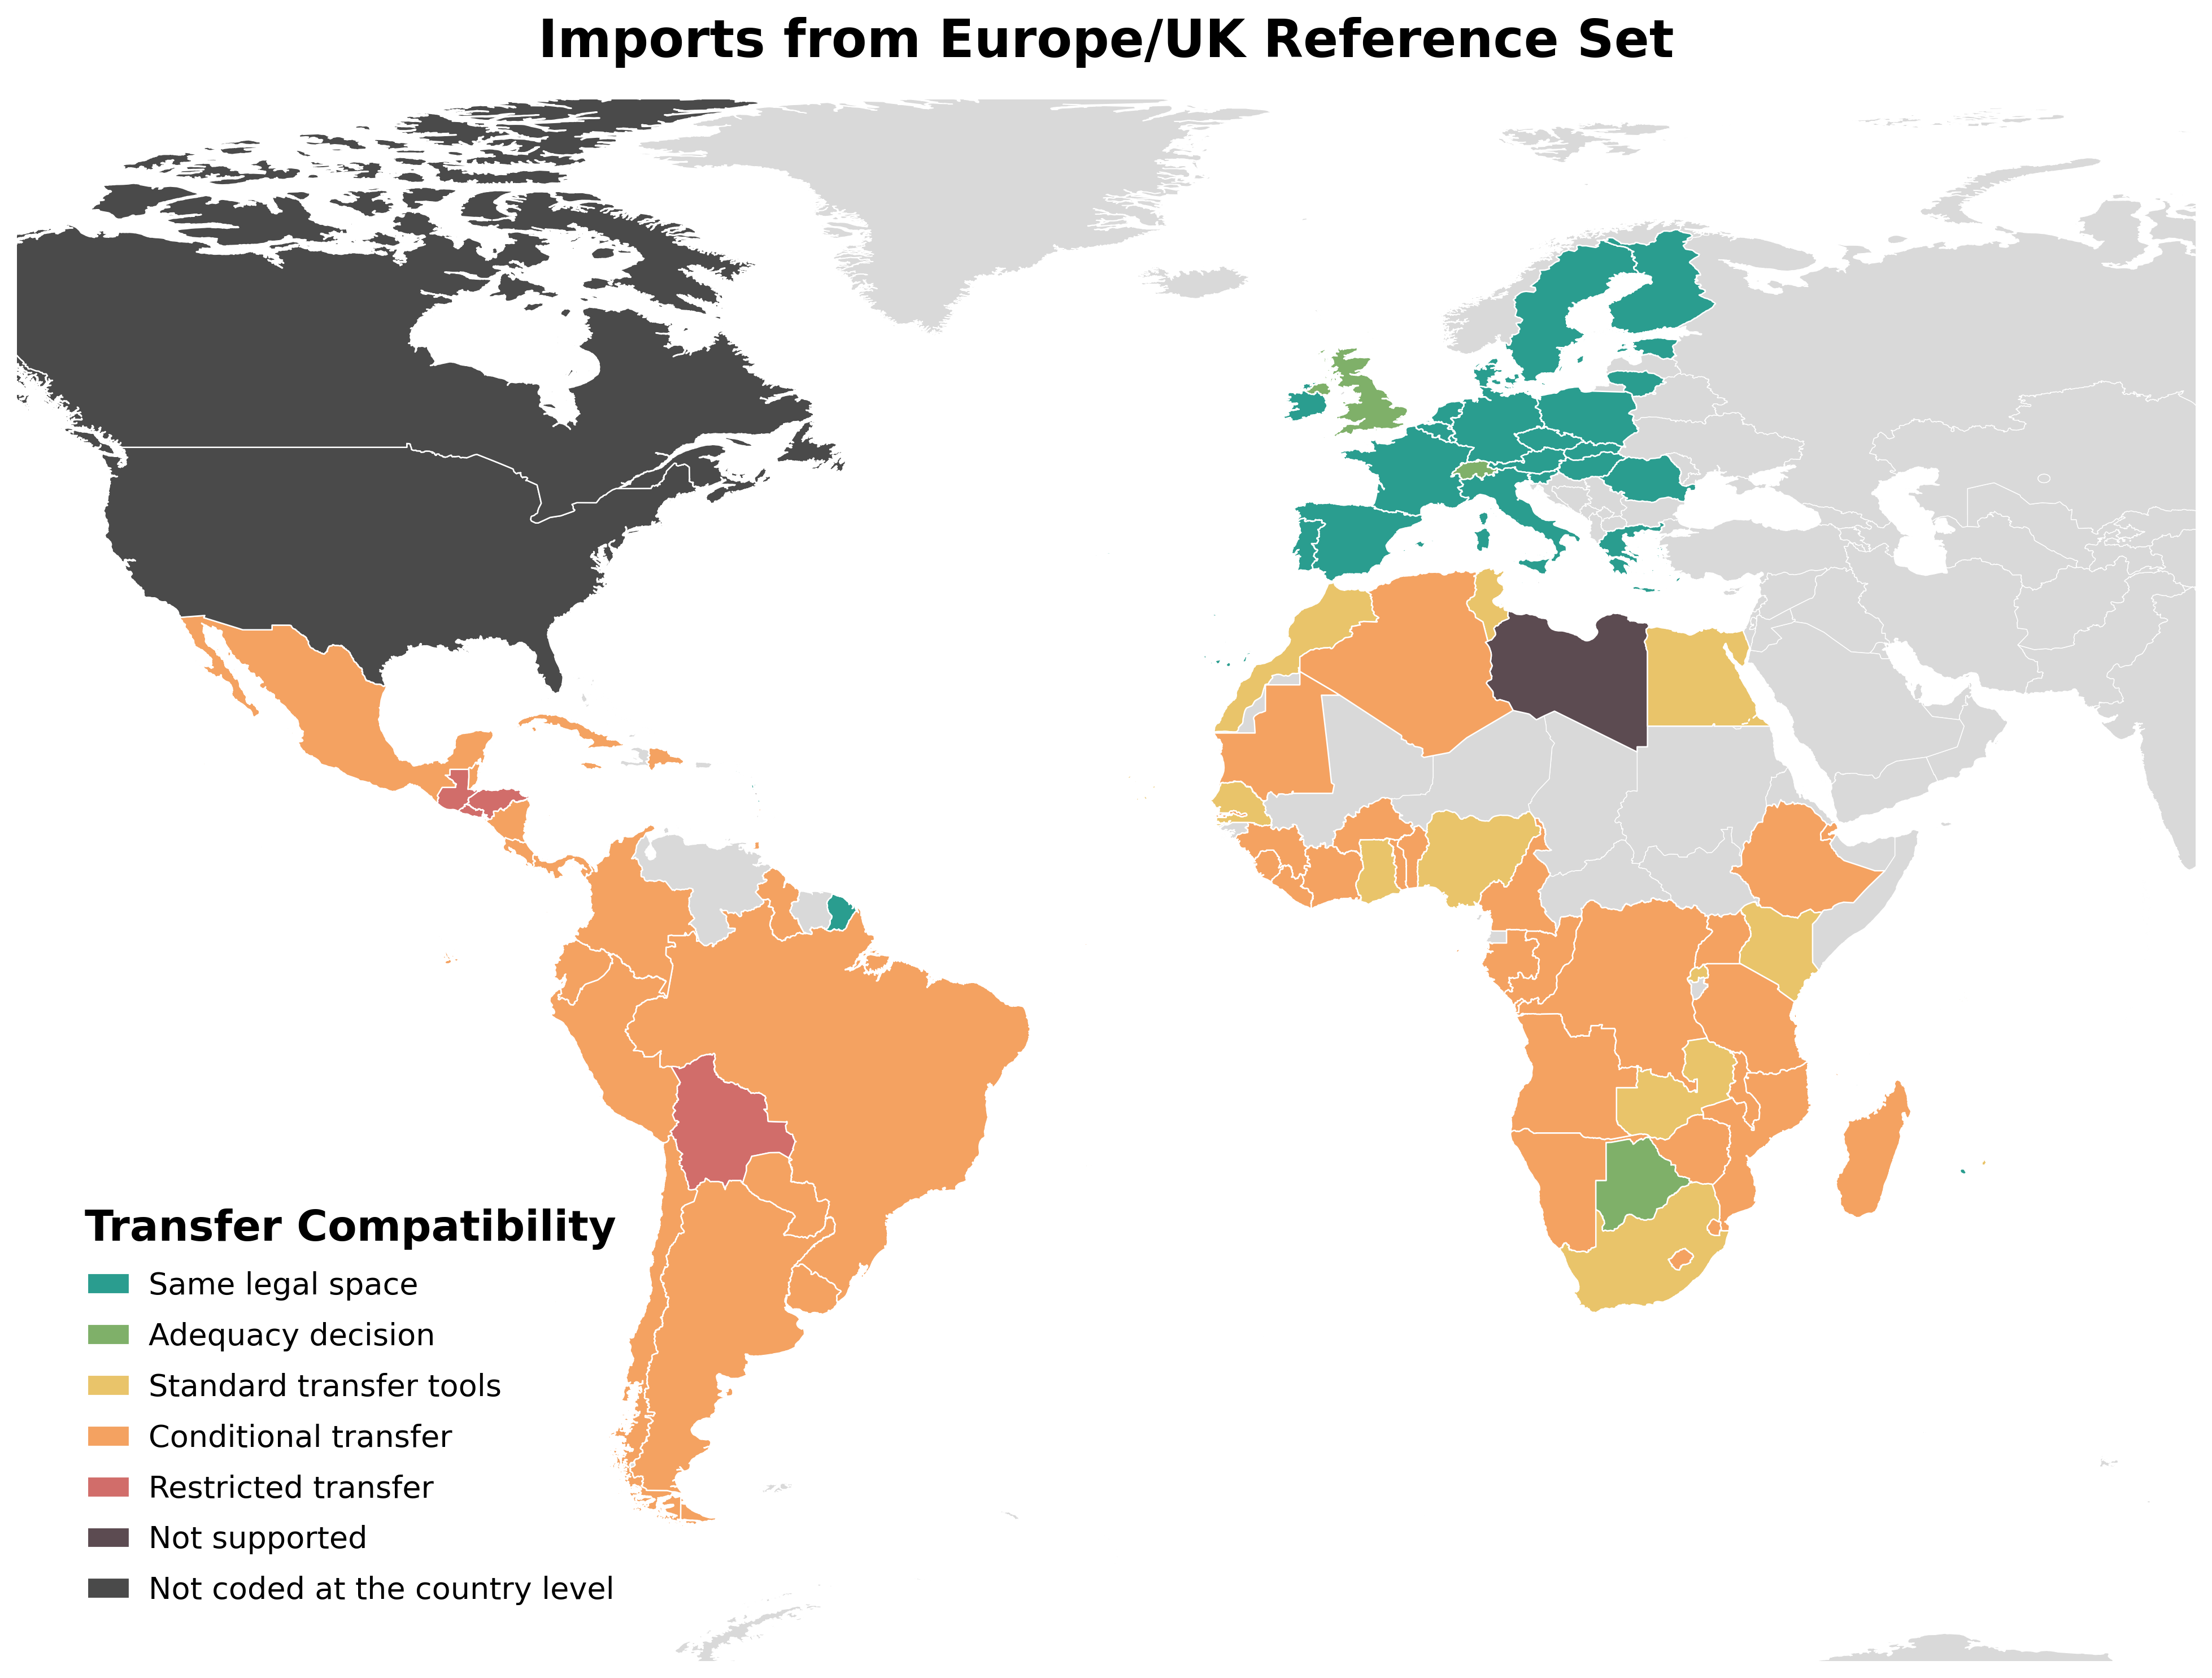

In [7]:
# USE USE
# 4. Specific-reference maps
# Publication-ready maps using the same compatibility classes as the matrix figures.

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd

# --------------------------------------------------
# Same compatibility colors as matrix figures
# --------------------------------------------------
LEVEL_COLORS = [
    "#2A9D8F",  # Same legal space
    "#7FB069",  # Adequacy decision
    "#E9C46A",  # Standard transfer tools
    "#F4A261",  # Conditional transfer
    "#D16D6A",  # Restricted transfer
    "#5C4B51",  # Not supported
]

PALETTE = {
    category: LEVEL_COLORS[i]
    for i, category in enumerate(CATEGORY_ORDER)
}

LEGEND_LABELS = [
    "Same legal space",
    "Adequacy decision",
    "Standard transfer tools",
    "Conditional transfer",
    "Restricted transfer",
    "Not supported",
]

# --------------------------------------------------
# Reference countries
# --------------------------------------------------
REFERENCE_COUNTRIES = [
    "United Kingdom",
    "Germany",
    "France",
    "Italy",
    "Spain",
    "Netherlands",
    "Belgium",
    "Sweden",
    "Austria",
    "Finland",
    "Ireland",
    "Denmark",
    "Luxembourg",
    "Czechia",
    "Portugal",
    "Lithuania",
    "Estonia",
    "Poland",
    "Greece",
    "Hungary",
    "Slovakia",
    "Slovenia",
    "Romania",
    "Switzerland",
]

REFERENCE_COUNTRIES = [
    c for c in REFERENCE_COUNTRIES
    if c in df_no_self.index and c in df_no_self.columns
]

print("Reference countries retained:")
print(REFERENCE_COUNTRIES)

def mode_across_values(values):
    values = pd.Series(values).dropna()
    if values.empty:
        return np.nan
    return values.value_counts().idxmax()

reference_df = pd.DataFrame({"country": df_no_self.index})

reference_df["export_to_reference_mode"] = [
    mode_across_values(df_no_self.loc[country, REFERENCE_COUNTRIES].values)
    if country in df_no_self.index else np.nan
    for country in df_no_self.index
]

reference_df["import_from_reference_mode"] = [
    mode_across_values(df_no_self.loc[REFERENCE_COUNTRIES, country].values)
    if country in df_no_self.columns else np.nan
    for country in df_no_self.index
]

reference_df["iso_a3"] = reference_df["country"].map(country_to_iso3)

reference_merged = world.merge(
    reference_df,
    left_on="ne_iso_a3",
    right_on="iso_a3",
    how="left",
)

# --------------------------------------------------
# Plotting function
# --------------------------------------------------
def plot_reference_mode_map(column, title, outfile_base):

    matched_geo = reference_merged[
        reference_merged[column].notna()
    ].copy()

    matched_geo["plot_color"] = matched_geo[column].map(PALETTE)

    fig, ax = plt.subplots(figsize=(16, 10), dpi=300)

    # Background countries
    world.plot(
        ax=ax,
        color="#D9D9D9",
        edgecolor="white",
        linewidth=0.35,
        zorder=1,
    )

    # Compatibility layer
    matched_geo.plot(
        ax=ax,
        color=matched_geo["plot_color"],
        edgecolor="white",
        linewidth=0.6,
        zorder=2,
    )

    # Force USA and Canada to dark gray
    usa_canada = world[
        world["ne_iso_a3"].isin(["USA", "CAN"])
    ]

    usa_canada.plot(
        ax=ax,
        color="#4A4A4A",
        edgecolor="white",
        linewidth=0.6,
        zorder=3,
    )

    # Zoom
    minx, miny, maxx, maxy = matched_geo.total_bounds

    ax.set_xlim(
        minx - (maxx - minx) * 0.08,
        maxx + (maxx - minx) * 0.08,
    )

    ax.set_ylim(
        miny - (maxy - miny) * 0.10,
        maxy + (maxy - miny) * 0.10,
    )

    ax.set_aspect("equal", adjustable="box")

    # Title
    ax.set_title(
        title,
        fontsize=22,
        fontweight="bold",
        pad=18,
    )

    ax.axis("off")

    # Legend
    legend_handles = [
        mpatches.Patch(
            facecolor=PALETTE[c],
            edgecolor="white",
            label=LEGEND_LABELS[i],
        )
        for i, c in enumerate(CATEGORY_ORDER)
    ]

    legend_handles.append(
        mpatches.Patch(
            facecolor="#4A4A4A",
            edgecolor="white",
            label="Not coded at the country level",
        )
    )

    legend = ax.legend(
        handles=legend_handles,
        title="Transfer Compatibility",
        loc="lower left",
        bbox_to_anchor=(0.02, 0.02),
        frameon=False,
        fontsize=13,
        title_fontsize=18,
        handlelength=1.4,
        handletextpad=0.6,
        borderpad=0.3,
        labelspacing=0.7,
    )

    legend.get_title().set_fontweight("bold")

    fig.tight_layout()

    savefig(fig, outfile_base)
    plt.show()
    plt.close(fig)

# --------------------------------------------------
# Generate figures
# --------------------------------------------------
plot_reference_mode_map(
    "export_to_reference_mode",
    "Exports to Europe/UK Reference Set",
    "03i_world_map_export_to_europeuk_reference_publication",
)

plot_reference_mode_map(
    "import_from_reference_mode",
    "Imports from Europe/UK Reference Set",
    "03j_world_map_import_from_europeuk_reference_publication",
)

## 3. Directional asymmetry network and summary table

The table reports asymmetry degree for the first 20 jurisdictions ranked by outgoing asymmetry count. A directed edge indicates that the origin-to-destination class has greater ordinal friction than the reverse transfer. Country colors follow the same hierarchical ordering as the matrix below.

,country,out_asymmetry_count,in_asymmetry_count,total_asymmetry_degree
0,Germany,24,1,25
13,Portugal,24,1,25
77,Dominican Rep.,24,0,24
1,France,24,1,25
23,Switzerland,24,1,25
21,Romania,24,1,25
20,Slovenia,24,1,25
19,Slovakia,24,1,25
18,Hungary,24,1,25
17,Greece,24,1,25


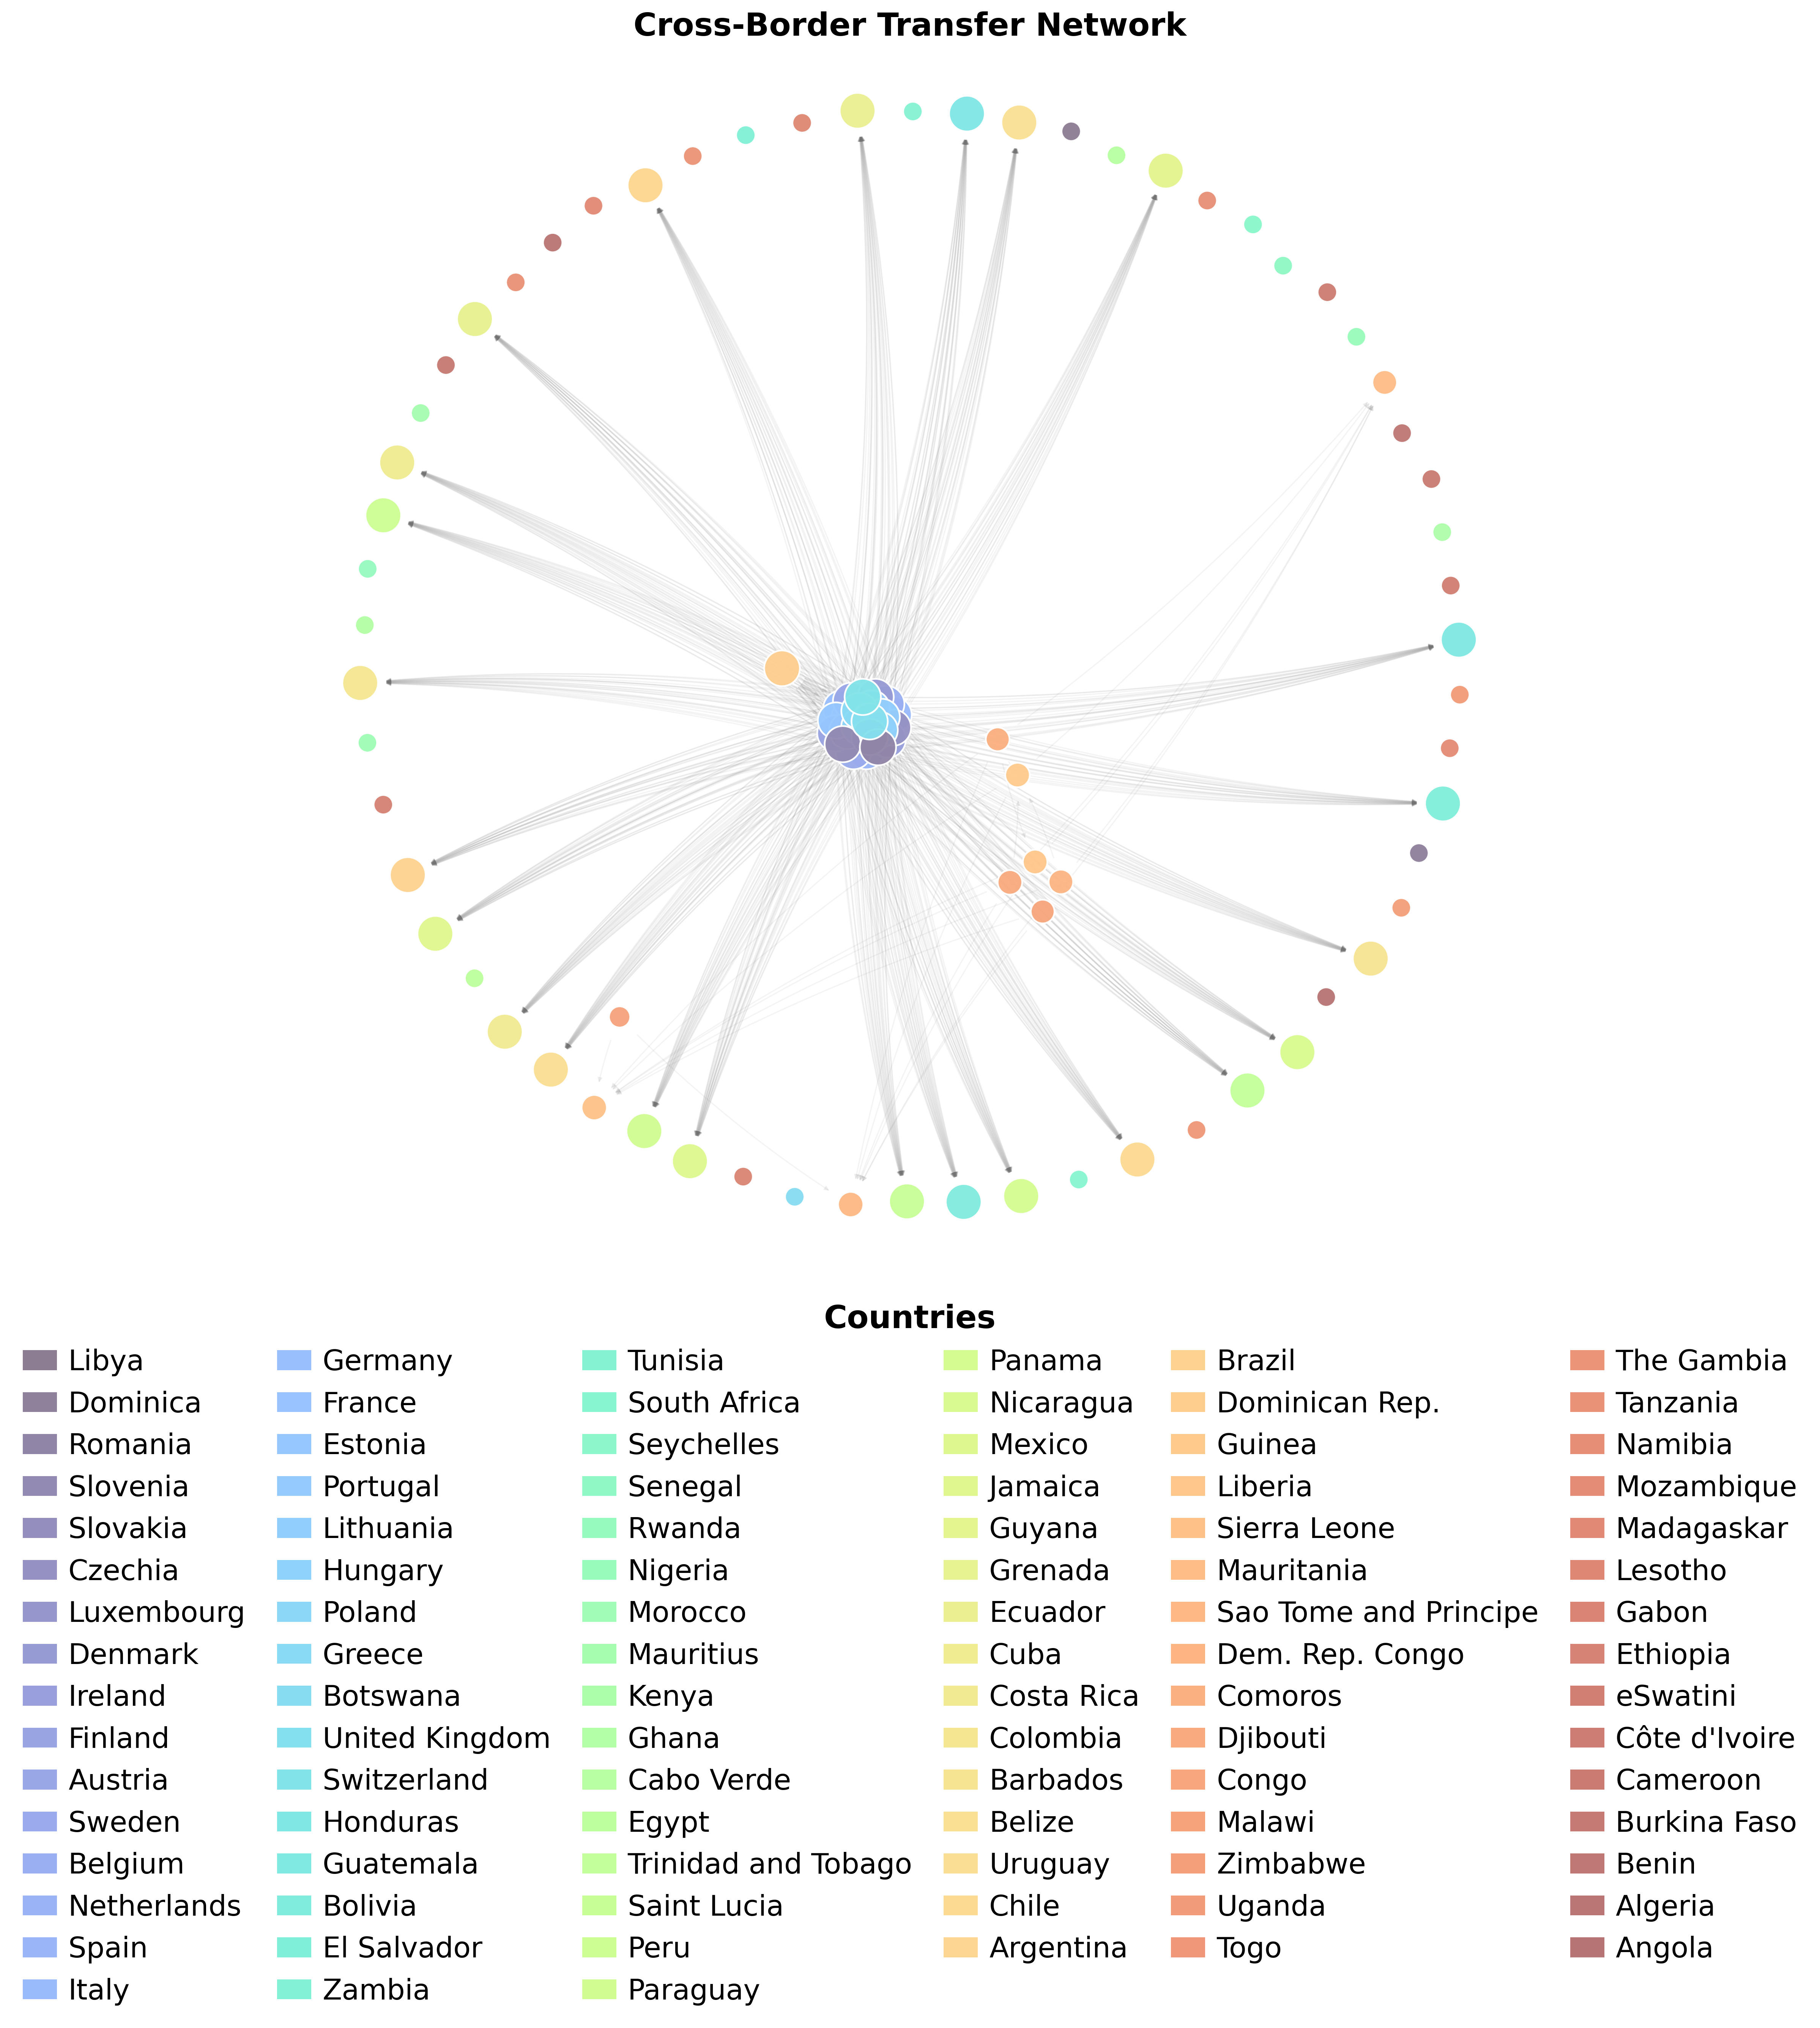

In [8]:
# USE USE
# Sparse asymmetry network with country colors matching the clustered matrix figure
# Keeps spring graph shape, reduces whitespace, and shortens visible edge lines
# No region colors and no country labels on nodes

import networkx as nx
from matplotlib.patches import Patch
from IPython.display import display, Image as IPythonImage
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import pdist

# ----------------------------
# Build asymmetry graph
# ----------------------------
G_asym = nx.DiGraph()

for country in asymmetry.index:
    G_asym.add_node(country)

for origin in asymmetry.index:
    for dest in asymmetry.columns:
        val = asymmetry.loc[origin, dest]
        if pd.notna(val) and val > 0:
            G_asym.add_edge(origin, dest, weight=float(val))

# ----------------------------
# Summary table
# ----------------------------
asym_degree_df = pd.DataFrame({
    "country": list(G_asym.nodes),
    "out_asymmetry_count": [G_asym.out_degree(n) for n in G_asym.nodes],
    "in_asymmetry_count": [G_asym.in_degree(n) for n in G_asym.nodes],
    "total_asymmetry_degree": [
        G_asym.out_degree(n) + G_asym.in_degree(n)
        for n in G_asym.nodes
    ],
}).sort_values("out_asymmetry_count", ascending=False)

display(asym_degree_df.head(20))

# ----------------------------
# Use same clustered country order as matrix figure
# ----------------------------
X = numeric_no_self.copy().astype(float)
X = X.apply(lambda col: col.fillna(col.median()), axis=0)
X = X.fillna(np.nanmedian(X.values))

row_dist = pdist(X.values, metric="euclidean")
row_linkage = linkage(row_dist, method="average")
row_order = leaves_list(row_linkage)

ordered_countries = list(X.index[row_order])
n = len(ordered_countries)

# Same softened turbo country colors as matrix figure
base = plt.cm.turbo(np.linspace(0, 1, n))
blend = 0.45

country_colors = base.copy()
country_colors[:, :3] = (
    (1 - blend) * base[:, :3] +
    blend * 1.0
)

country_color_map = {
    country: country_colors[i]
    for i, country in enumerate(ordered_countries)
}

node_colors = [
    country_color_map.get(node, "#7D8FA6")
    for node in G_asym.nodes
]

# ----------------------------
# Centrality and node sizing
# ----------------------------
if G_asym.number_of_edges() > 0:
    betweenness = nx.betweenness_centrality(
        G_asym,
        weight="weight",
        normalized=True
    )
else:
    betweenness = {node: 0 for node in G_asym.nodes}

degree_dict = {
    node: G_asym.out_degree(node) + G_asym.in_degree(node)
    for node in G_asym.nodes
}

node_sizes = [
    150
    + 1500 * betweenness.get(node, 0)
    + 15 * degree_dict[node]
    for node in G_asym.nodes
]

# ----------------------------
# Layout
# ----------------------------
# Keep original spread so center circles do NOT overlap more
pos = nx.spring_layout(
    G_asym,
    k=4.5,
    iterations=500,
    seed=7,
    weight=None
)

edge_widths = [
    0.35 + 0.45 * G_asym[u][v].get("weight", 1.0)
    for u, v in G_asym.edges
]

# ----------------------------
# Plot
# ----------------------------
fig, ax = plt.subplots(figsize=(18, 18), dpi=300)

nx.draw_networkx_edges(
    G_asym,
    pos,
    ax=ax,
    arrows=True,
    arrowsize=6,
    width=edge_widths,
    alpha=0.08,
    edge_color="0.45",
    connectionstyle="arc3,rad=0.06",
    min_source_margin=16,   # shortens visible lines without moving nodes
    min_target_margin=16,   # increase to 20–25 if you want even shorter lines
)

nx.draw_networkx_nodes(
    G_asym,
    pos,
    ax=ax,
    node_size=node_sizes,
    node_color=node_colors,
    edgecolors="white",
    linewidths=1.1,
    alpha=0.96,
)

# ----------------------------
# Country legend using same order/colors as matrix
# ----------------------------
legend_elements = [
    Patch(
        facecolor=country_color_map[country],
        label=country
    )
    for country in ordered_countries
    if country in G_asym.nodes
]

legend = ax.legend(
    handles=legend_elements,
    title="Countries",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.025),
    frameon=False,
    ncol=6,
    columnspacing=1.1,
    handlelength=1.2,
    handletextpad=0.4,
    prop={"size": 18},
    title_fontproperties={"size": 20, "weight": "bold"},
)

ax.set_title(
    "Cross-Border Transfer Network",
    fontsize=20,
    fontweight="bold",
    pad=20,
)

# ----------------------------
# Tight crop around graph without changing layout
# ----------------------------
xy = np.array(list(pos.values()))

pad_x = 0.04 * (xy[:, 0].max() - xy[:, 0].min())
pad_y = 0.04 * (xy[:, 1].max() - xy[:, 1].min())

ax.set_xlim(xy[:, 0].min() - pad_x, xy[:, 0].max() + pad_x)
ax.set_ylim(xy[:, 1].min() - pad_y, xy[:, 1].max() + pad_y)

ax.set_aspect("equal")
ax.margins(0)
ax.axis("off")

fig.tight_layout()

fig_name = "04d_sparse_asymmetry_network_country_colors_matching_matrix_short_edges"
savefig(fig, fig_name)

plt.show()
plt.close(fig)


## 4. Clustered directional compatibility matrix

Average-linkage hierarchical clustering orders jurisdictions by Euclidean distance between their imputed outgoing profiles. The displayed matrix retains the original compatibility values.

In [ ]:
# USE USE
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import pdist
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap, BoundaryNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------
# Custom compatibility colors
# ----------------------------
LEVEL_COLORS = [
    "#2A9D8F",  # teal
    "#7FB069",  # sage
    "#E9C46A",  # sand
    "#F4A261",  # amber
    "#D16D6A",  # muted coral
    "#5C4B51",  # charcoal plum
]
CMAP = ListedColormap(LEVEL_COLORS)
NORM = BoundaryNorm(
    boundaries=np.arange(-0.5, len(LEVEL_COLORS) + 0.5, 1),
    ncolors=len(LEVEL_COLORS)
)

X = numeric_no_self.copy().astype(float)

# Fill missing values
X = X.apply(lambda col: col.fillna(col.median()), axis=0)
X = X.fillna(np.nanmedian(X.values))

# Cluster countries
row_dist = pdist(X.values, metric="euclidean")
row_linkage = linkage(row_dist, method="average")
row_order = leaves_list(row_linkage)

ordered_countries = X.index[row_order]
X_clustered = numeric.loc[ordered_countries, ordered_countries]

n = len(ordered_countries)
country_ids = np.arange(n)

# Softer categorical country colors
base = plt.cm.turbo(np.linspace(0, 1, n))

blend = 0.45   # blend toward white

country_colors = base.copy()
country_colors[:, :3] = (
    (1 - blend) * base[:, :3] +
    blend * 1.0
)

country_cmap = ListedColormap(country_colors)
fig, ax = plt.subplots(figsize=(24, 24), dpi=300)

# Main heatmap
im = ax.imshow(
    X_clustered.values.astype(float),
    cmap=CMAP,
    norm=NORM,
    interpolation="none",
    aspect="equal",
)

# Attach axes directly to matrix
divider = make_axes_locatable(ax)

ax_top = divider.append_axes(
    "top",
    size="3%",
    pad=0.03,
    sharex=ax
)

ax_left = divider.append_axes(
    "left",
    size="3%",
    pad=0.03,
    sharey=ax
)

# Top country color strip
ax_top.imshow(
    country_ids.reshape(1, n),
    cmap=country_cmap,
    interpolation="none",
    aspect="auto",
)

# Left country color strip
ax_left.imshow(
    country_ids.reshape(n, 1),
    cmap=country_cmap,
    interpolation="none",
    aspect="auto",
)

# Force exact alignment
ax.set_xlim(-0.5, n - 0.5)
ax.set_ylim(n - 0.5, -0.5)
ax_top.set_xlim(ax.get_xlim())
ax_left.set_ylim(ax.get_ylim())

# Remove ticks
ax.set_xticks([])
ax.set_yticks([])
ax_top.set_xticks([])
ax_top.set_yticks([])
ax_left.set_xticks([])
ax_left.set_yticks([])

# Country legend
legend_elements = [
    Patch(facecolor=country_colors[i], label=country)
    for i, country in enumerate(ordered_countries)
]

legend = ax.legend(
    handles=legend_elements,
    title="Countries",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.05),
    frameon=False,
    ncol=6,
    columnspacing=1.2,
    handlelength=1.2,
    handletextpad=0.5,
    prop={"size": 18},
    title_fontproperties={"size": 20, "weight": "bold"},
)
# Compatibility legend
legend_labels = [
    "Same legal space",
    "Adequacy decision",
    "Standard transfer tools",
    "Conditional transfer",
    "Restricted transfer",
    "Not supported",
]

cbar = fig.colorbar(
    im,
    ax=ax,
    ticks=range(len(legend_labels)),
    fraction=0.07,
    pad=0.05,
    shrink=0.50,
)

cbar.set_ticks(range(len(legend_labels)))
cbar.set_ticklabels(legend_labels)

cbar.ax.tick_params(labelsize=18)

cbar.set_label(
    "Transfer Compatibility",
    fontsize=20,
    fontweight="bold",
    labelpad=20,
)

cbar.ax.yaxis.set_label_position("left")

# Title and axis labels
ax.set_title(
    "Cross-Border Data Transfer Compatibility",
    fontsize=22,
    fontweight="bold",
    pad=40,
)

ax.set_xlabel(
    "Destination Country",
    fontsize=22,
    fontweight="bold",
    labelpad=15,
)

ax.set_ylabel(
    "Origin Country",
    fontsize=22,
    fontweight="bold",
    labelpad=40,
)

plt.subplots_adjust(
    bottom=0.28,
    left=0.24,
    right=0.90,
    top=0.90,
)

plt.rcParams["font.family"] = "Arial"

savefig(fig, "06b_clustered_directional_heatmap_country_soft_colors")
plt.show()
plt.close(fig)